# Exploring the Uncertainty Principle with Fourier Transform

This notebook demonstrates the uncertainty principle using a Gaussian function and its Fourier transform. We compute:
- $\int x^2 |f(x)|^2 dx$
- $\int \omega^2 |\hat{f}(\omega)|^2 d\omega$

and show their product, which is bounded below by $1/4$ for a normalized Gaussian.

## Visual Intuition for the Uncertainty Principle

- The uncertainty principle says that a function and its Fourier transform cannot both be sharply localized.
- If $|f(x)|^2$ is very concentrated (narrow), its Fourier transform $|\hat{f}(\omega)|^2$ will be spread out (broad), and vice versa.
- The integrals $\int x^2 |f(x)|^2 dx$ and $\int \omega^2 |\hat{f}(\omega)|^2 d\omega$ measure the “width” or “spread” of the function in each domain.
- Their product has a lower bound: you cannot make both spreads arbitrarily small at the same time.

Below, we visualize this by changing the width of the Gaussian and observing how the spread in frequency changes.

<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\o'
<>:29: SyntaxWarning: invalid escape sequence '\o'
<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\o'
<>:29: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_175925/2718458178.py:22: SyntaxWarning: invalid escape sequence '\s'
  plt.title(f'$|f(x)|^2$, $\sigma$={sigma}')
/tmp/ipykernel_175925/2718458178.py:28: SyntaxWarning: invalid escape sequence '\h'
  plt.title(f'$|\hat{{f}}(\omega)|^2$, $\sigma$={sigma}')
/tmp/ipykernel_175925/2718458178.py:28: SyntaxWarning: invalid escape sequence '\o'
  plt.title(f'$|\hat{{f}}(\omega)|^2$, $\sigma$={sigma}')
/tmp/ipykernel_175925/2718458178.py:29: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('$\omega$')


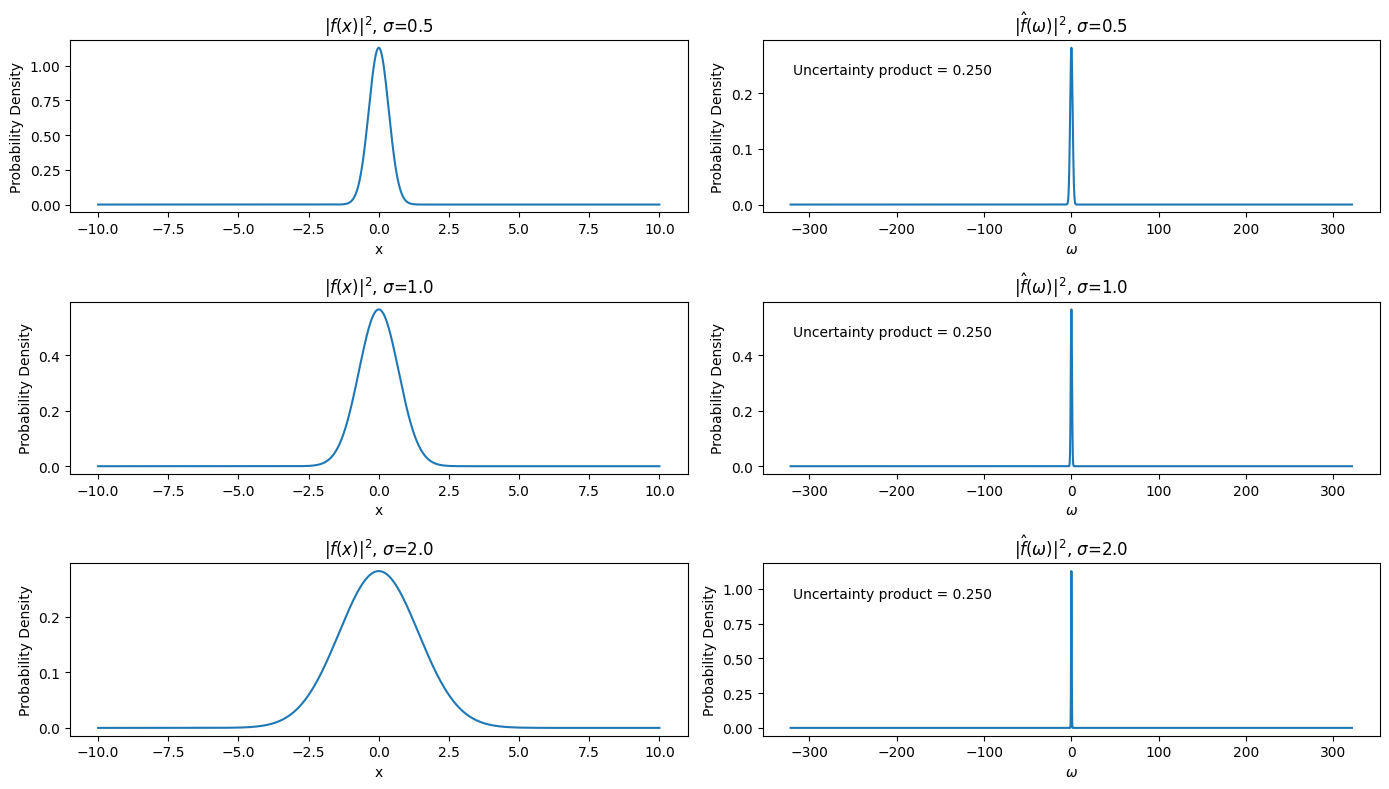

In [3]:
# Visualizing the trade-off between position and frequency spread
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, fftshift, ifftshift

sigmas = [0.5, 1.0, 2.0]
x = np.linspace(-10, 10, 2048)
N = x.size
dx = x[1] - x[0]
w = fftshift(fftfreq(N, d=dx)) * 2 * np.pi

plt.figure(figsize=(14, 8))
for i, sigma in enumerate(sigmas):
    f_x = (1/(np.pi*sigma**2)**0.25) * np.exp(-x**2/(2*sigma**2))
    F_w = fftshift(fft(ifftshift(f_x))) * dx / (2*np.pi)**0.5
    x2_fx2 = np.sum(x**2 * np.abs(f_x)**2) * dx
    w2_Fw2 = np.sum(w**2 * np.abs(F_w)**2) * (w[1] - w[0])
    uncertainty_product = x2_fx2 * w2_Fw2
    
    plt.subplot(3, 2, 2*i+1)
    plt.plot(x, np.abs(f_x)**2)
    plt.title(f'$|f(x)|^2$, $\sigma$={sigma}')
    plt.xlabel('x')
    plt.ylabel('Probability Density')
    
    plt.subplot(3, 2, 2*i+2)
    plt.plot(w, np.abs(F_w)**2)
    plt.title(f'$|\hat{{f}}(\omega)|^2$, $\sigma$={sigma}')
    plt.xlabel('$\omega$')
    plt.ylabel('Probability Density')
    plt.text(0.05, 0.8, f'Uncertainty product = {uncertainty_product:.3f}', transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()

∫ x^2 |f(x)|^2 dx = 0.5000
∫ ω^2 |F(ω)|^2 dω = 0.5000
Uncertainty product = 0.2500


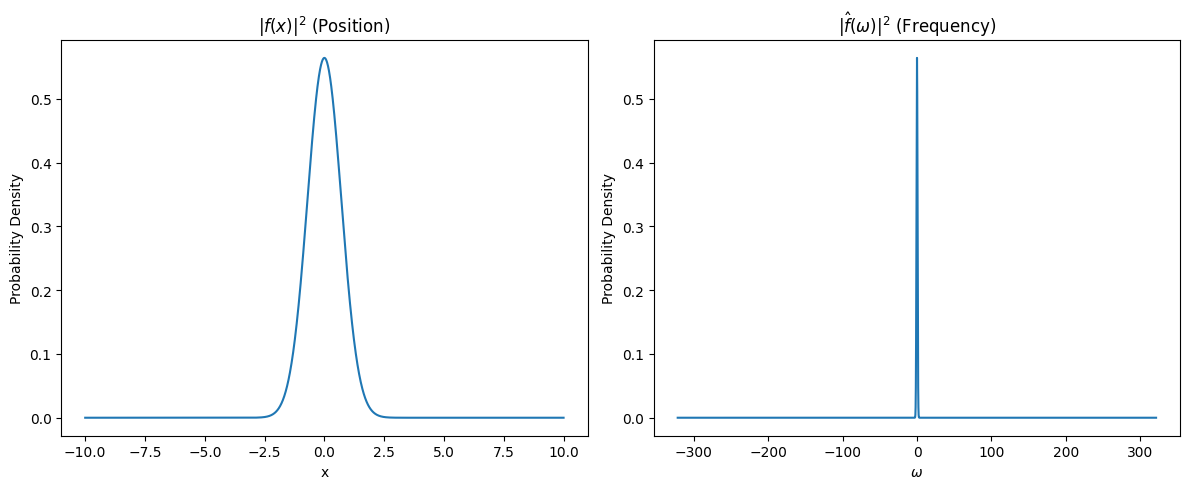

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, fftshift, ifft, ifftshift

# Define the Gaussian function
sigma = 1.0
x = np.linspace(-10, 10, 2048)
f_x = (1/(np.pi*sigma**2)**0.25) * np.exp(-x**2/(2*sigma**2))

# Compute the Fourier transform
# Normalization for continuous FT
N = x.size
dx = x[1] - x[0]
w = fftshift(fftfreq(N, d=dx)) * 2 * np.pi
F_w = fftshift(fft(ifftshift(f_x))) * dx / (2*np.pi)**0.5

# Compute the integrals
x2_fx2 = np.sum(x**2 * np.abs(f_x)**2) * dx
w2_Fw2 = np.sum(w**2 * np.abs(F_w)**2) * (w[1] - w[0])

uncertainty_product = x2_fx2 * w2_Fw2

print(f"∫ x^2 |f(x)|^2 dx = {x2_fx2:.4f}")
print(f"∫ ω^2 |F(ω)|^2 dω = {w2_Fw2:.4f}")
print(f"Uncertainty product = {uncertainty_product:.4f}")

# Plot the function and its Fourier transform
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(x, np.abs(f_x)**2)
plt.title(r'$|f(x)|^2$ (Position)')
plt.xlabel('x')
plt.ylabel('Probability Density')

plt.subplot(1,2,2)
plt.plot(w, np.abs(F_w)**2)
plt.title(r'$|\hat{f}(\omega)|^2$ (Frequency)')
plt.xlabel(r'$\omega$')
plt.ylabel('Probability Density')
plt.tight_layout()
plt.show()

**Instructions:**

- Run the code cell above to see the uncertainty principle in action for a Gaussian function.
- You can modify the function $f(x)$ or the parameter $\sigma$ to see how the uncertainty product changes.
- The product should always be greater than or equal to $1/4$ (for normalized Gaussians, it is exactly $1/4$).